In [242]:
from google.colab import drive
import zipfile
import os

# Mount Google Drive
drive.mount('/content/drive')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [243]:
# IMPORTANT: Update this path to where your 'all_mtp_data.zip' is located in your Google Drive.
# For example: '/content/drive/MyDrive/my_data/all_mtp_data.zip'
drive_zip_path = '/content/drive/MyDrive/al_mtp_data.zip'

if os.path.exists(drive_zip_path):
    print(f"Extracting {drive_zip_path}...")
    with zipfile.ZipFile(drive_zip_path, 'r') as zf:
        zf.extractall('.') # Extract to the current working directory
    print("Extraction complete!")
else:
    print(f"Error: Zip file not found at {drive_zip_path}. Please update the 'drive_zip_path' variable with the correct location.")

Extracting /content/drive/MyDrive/al_mtp_data.zip...
Extraction complete!


In [244]:
import os

# List the contents of the current directory to see what was extracted
print('Contents of the current directory after extraction:')
for item in os.listdir('.'):
    print(item)

    # List the contents of the 'al_mtp_data' directory
print('Contents of the al_mtp_data directory:')
for item in os.listdir('al_mtp_data'):
    print(item)

Contents of the current directory after extraction:
.config
drive
al_mtp_data
sample_data
Contents of the al_mtp_data directory:
ms
ucihar
hhar
pamap2


In [245]:
import os

# List the contents of the 'al_mtp_data/ucihar' directory
print('Contents of the al_mtp_data/ucihar directory:')
for item in os.listdir('al_mtp_data/ucihar'):
    print(item)

Contents of the al_mtp_data/ucihar directory:
data


In [246]:
import os

# List the contents of the 'al_mtp_data/ucihar/data' directory
print('Contents of the al_mtp_data/ucihar/data directory:')
for item in os.listdir('al_mtp_data/ucihar/data'):
    print(item)

Contents of the al_mtp_data/ucihar/data directory:
wlkdown.csv
sit.csv
std.csv
wlkup.csv
wlk.csv
lay.csv


In [247]:
import pandas as pd

# Define the path to the 'std.csv' file
file_path = 'al_mtp_data/ucihar/data/std.csv'

# Load the CSV file into a Pandas DataFrame
df_ms_std = pd.read_csv(file_path)

# Display the first 5 rows of the DataFrame
print(f"First 5 rows of {file_path}:")
print(df_ms_std.head())

First 5 rows of al_mtp_data/ucihar/data/std.csv:
          x         y         z
0  0.983333 -0.327778 -0.027778
1  0.981945 -0.326389 -0.022222
2  0.973611 -0.334722 -0.022222
3  0.970833 -0.327778 -0.019444
4  0.970833 -0.322222 -0.019444


### Data Loading and Labeling for Multi-Class Classification

To address the issue of dummy labels, we will now load all activity CSV files, assign them meaningful numerical labels, and combine them into a single DataFrame. This will enable us to train a multi-class classification model.

In [248]:
import pandas as pd
import os

# Define the base directory where the activity CSVs are located
data_dir = 'al_mtp_data/ucihar/data'

# Dynamically create activity_labels based on existing CSV files
activity_labels = {}
label_counter = 0

print(f"Searching for activity files in: {data_dir}")

# List all files in the data directory and filter for .csv files
csv_files = [f for f in os.listdir(data_dir) if f.endswith('.csv')]

# Sort files for consistent label assignment if the order matters (optional but good practice)
csv_files.sort()

for csv_file in csv_files:
    activity_name = os.path.splitext(csv_file)[0] # Get activity name without .csv extension
    activity_labels[activity_name] = label_counter
    label_counter += 1

# The total number of unique classes
num_classes = len(activity_labels)
print(f"Number of classes defined: {num_classes}")
print(f"Detected activities and their labels: {activity_labels}")

all_dfs = []
# Loop through each detected activity and load its data
for activity_name, label_id in activity_labels.items():
    file_path = os.path.join(data_dir, f'{activity_name}.csv')
    # No need for os.path.exists() check here, as activity_labels was built from existing files
    df_activity = pd.read_csv(file_path)
    df_activity['label'] = label_id # Assign the corresponding numerical label
    all_dfs.append(df_activity)
    print(f"Loaded {activity_name}.csv with label {label_id}. Shape: {df_activity.shape}")

# Concatenate all activity DataFrames into a single DataFrame
df_combined = pd.concat(all_dfs, ignore_index=True)

print(f"\nCombined DataFrame shape: {df_combined.shape}")
print("Combined DataFrame head:")
display(df_combined.head())
print("Combined DataFrame tail:")
display(df_combined.tail())

# Separate features (X) and labels (y)
X = df_combined.drop(columns=['label'])
y = df_combined['label']

print(f"Shape of features (X): {X.shape}")
print(f"Shape of labels (y): {y.shape}")

Searching for activity files in: al_mtp_data/ucihar/data
Number of classes defined: 6
Detected activities and their labels: {'lay': 0, 'sit': 1, 'std': 2, 'wlk': 3, 'wlkdown': 4, 'wlkup': 5}
Loaded lay.csv with label 0. Shape: (28033, 4)
Loaded sit.csv with label 1. Shape: (26948, 4)
Loaded std.csv with label 2. Shape: (28513, 4)
Loaded wlk.csv with label 3. Shape: (27205, 4)
Loaded wlkdown.csv with label 4. Shape: (16185, 4)
Loaded wlkup.csv with label 5. Shape: (17646, 4)

Combined DataFrame shape: (144530, 4)
Combined DataFrame head:


,x,y,z,label
0,0.420833,0.901389,-0.058333,0
1,0.486111,0.940278,-0.091667,0
2,0.458333,1.004167,-0.120833,0
3,0.354167,1.127778,-0.073611,0
4,0.269444,1.209722,-0.036111,0


Combined DataFrame tail:


,x,y,z,label
144525,0.950000,-0.443056,-0.187500,5
144526,0.880556,-0.390278,-0.156944,5
144527,0.834722,-0.358333,-0.098611,5
144528,0.802778,-0.329167,-0.104167,5
144529,0.770833,-0.287500,-0.098611,5


Shape of features (X): (144530, 3)
Shape of labels (y): (144530,)


### Setting Random Seed = 32
 for Reproducibility

To ensure reproducibility and evaluate model stability, we will now introduce a `RANDOM_SEED` that will be used for data splitting and model initialization. You can change this value and re-run the subsequent cells to test different random initializations.

In [249]:
import numpy as np
import torch

# --- SET YOUR DESIRED RANDOM SEED HERE ---
RANDOM_SEED = 32
print(f"Using RANDOM_SEED: {RANDOM_SEED}")

# Set random seeds for reproducibility
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

Using RANDOM_SEED: 32


In [250]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# We use the X and y from the combined DataFrame.
# stratify=y ensures that the proportion of activity labels is the same in train and test sets.
# test_size= 0.9 means that 90% of your total data will be allocated to the testing set.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=RANDOM_SEED, stratify=y)

print(f"Shape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

Shape of training features (X_train): (14453, 3)
Shape of training labels (y_train): (14453,)
Shape of testing features (X_test): (130077, 3)
Shape of testing labels (y_test): (130077,)


In [251]:
from sklearn.model_selection import train_test_split

# Split the training data to create a validation set
# We use the X_train and y_train from the previous split.
# stratify=y_train ensures that the proportion of activity labels is the same in the new train and val sets.
# test_size=0.1 means 10% of the *current* X_train will go to the validation set
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train)

print(f"Shape of new training features (X_train): {X_train.shape}")
print(f"Shape of new training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")

Shape of new training features (X_train): (13007, 3)
Shape of new training labels (y_train): (13007,)
Shape of validation features (X_val): (1446, 3)
Shape of validation labels (y_val): (1446,)


In [252]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Define windowing parameters
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    # Iterate through the data to create windows
    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        # For labels, we take the label of the last element in the window as representative
        # or the most frequent label. For HAR, often the label at the window's center or end is used.
        # Here, we'll use the label of the last element in the window.
        window_y = data_y[i + window_size - 1]
        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the datasets, now including labels
X_train_windows, y_train_windows = create_windows_with_labels(X_train, y_train, window_size, stride)
X_val_windows, y_val_windows = create_windows_with_labels(X_val, y_val, window_size, stride)
X_test_windows, y_test_windows = create_windows_with_labels(X_test, y_test, window_size, stride)

print(f"Shape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

Shape of X_train_windows: (202, 128, 3)
Shape of y_train_windows: (202,)
Shape of X_val_windows: (21, 128, 3)
Shape of y_val_windows: (21,)
Shape of X_test_windows: (2031, 128, 3)
Shape of y_test_windows: (2031,)
Number of training batches: 4
Number of validation batches: 1
Number of testing batches: 32


Now that the data is prepared with windowing and DataLoaders, I will define the 1D Convolutional Neural Network (CNN) architecture in PyTorch, which is commonly used for time-series tasks like Human Activity Recognition.

In [253]:
import copy

class CNN1D(nn.Module):
    def __init__(self, input_features, num_classes, window_size):
        super(CNN1D, self).__init__()
        # Input to Conv1d expects (batch_size, channels, sequence_length)
        # Here, channels = input_features (e.g., x, y, z), sequence_length = window_size
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        # Calculate the size of the flattened layer after convolutional and pooling operations
        # The window_size is halved by each MaxPool1d layer with kernel_size=2, stride=2
        flattened_size = 128 * (window_size // 4) # Assuming window_size is divisible by 4

        self.fc1 = nn.Linear(flattened_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # x shape: (batch_size, window_size, input_features)
        # Permute to (batch_size, input_features, window_size)
        x = x.permute(0, 2, 1)

        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        x = x.reshape(x.size(0), -1) # Flatten the tensor
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
# Now using the actual num_classes derived from our loaded activity data
cnn_model = CNN1D(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model.to(device);

print(cnn_model)
print(f"Model will be trained on: {device}")

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Suitable for classification tasks
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)


def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, patience=5, min_delta=0.001):
    model.train() # Set the model to training mode
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.4f}")

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples
        print(f"Validation Loss: {val_epoch_loss:.4f}, Validation Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=5, min_delta=0.001)

CNN1D(
  (conv1): Conv1d(3, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu1): ReLU()
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu2): ReLU()
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=6, bias=True)
)
Model will be trained on: cuda
Epoch 1/100, Loss: 1.8263, Accuracy: 0.1881
Validation Loss: 1.7479, Validation Accuracy: 0.1905
Epoch 2/100, Loss: 1.7563, Accuracy: 0.2426
Validation Loss: 1.8170, Validation Accuracy: 0.1905
Epoch 3/100, Loss: 1.7475, Accuracy: 0.3168
Validation Loss: 1.8209, Validation Accuracy: 0.1905
Epoch 4/100, Loss: 1.7219, Accuracy: 0.3416
Validation Loss: 1.7723, Validation Accuracy: 0.1905
Epoch 5/100, Loss: 1.6808, Accuracy: 0

### Model Evaluation on Test Set

In [254]:
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"Test Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss, test_accuracy = evaluate_model(trained_model, test_loader, criterion)


Test Loss: 1.7671, Test Accuracy: 0.2014


**random seed = 42**


In [255]:
import numpy as np
import torch

# --- SET YOUR DESIRED RANDOM SEED HERE ---
RANDOM_SEED = 42
print(f"Using RANDOM_SEED: {RANDOM_SEED}")

# Set random seeds for reproducibility
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

Using RANDOM_SEED: 42


In [256]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# We use the X and y from the combined DataFrame.
# stratify=y ensures that the proportion of activity labels is the same in train and test sets.
# test_size=0.9 means 10% for training/validation, 90% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=RANDOM_SEED, stratify=y)

print(f"Shape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

Shape of training features (X_train): (14453, 3)
Shape of training labels (y_train): (14453,)
Shape of testing features (X_test): (130077, 3)
Shape of testing labels (y_test): (130077,)


In [257]:
from sklearn.model_selection import train_test_split

# Split the training data to create a validation set
# We use the X_train and y_train from the previous split.
# stratify=y_train ensures that the proportion of activity labels is the same in the new train and val sets.
# test_size=0.1 means 10% of the *current* X_train will go to the validation set
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train)

print(f"Shape of new training features (X_train): {X_train.shape}")
print(f"Shape of new training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")

Shape of new training features (X_train): (13007, 3)
Shape of new training labels (y_train): (13007,)
Shape of validation features (X_val): (1446, 3)
Shape of validation labels (y_val): (1446,)


In [258]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Define windowing parameters
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    # Iterate through the data to create windows
    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        # For labels, we take the label of the last element in the window as representative
        # or the most frequent label. For HAR, often the label at the window's center or end is used.
        # Here, we'll use the label of the last element in the window.
        window_y = data_y[i + window_size - 1]
        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the datasets, now including labels
X_train_windows, y_train_windows = create_windows_with_labels(X_train, y_train, window_size, stride)
X_val_windows, y_val_windows = create_windows_with_labels(X_val, y_val, window_size, stride)
X_test_windows, y_test_windows = create_windows_with_labels(X_test, y_test, window_size, stride)

print(f"Shape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

Shape of X_train_windows: (202, 128, 3)
Shape of y_train_windows: (202,)
Shape of X_val_windows: (21, 128, 3)
Shape of y_val_windows: (21,)
Shape of X_test_windows: (2031, 128, 3)
Shape of y_test_windows: (2031,)
Number of training batches: 4
Number of validation batches: 1
Number of testing batches: 32


In [259]:
import copy

class CNN1D(nn.Module):
    def __init__(self, input_features, num_classes, window_size):
        super(CNN1D, self).__init__()
        # Input to Conv1d expects (batch_size, channels, sequence_length)
        # Here, channels = input_features (e.g., x, y, z), sequence_length = window_size
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        # Calculate the size of the flattened layer after convolutional and pooling operations
        # The window_size is halved by each MaxPool1d layer with kernel_size=2, stride=2
        flattened_size = 128 * (window_size // 4) # Assuming window_size is divisible by 4

        self.fc1 = nn.Linear(flattened_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # x shape: (batch_size, window_size, input_features)
        # Permute to (batch_size, input_features, window_size)
        x = x.permute(0, 2, 1)

        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        x = x.reshape(x.size(0), -1) # Flatten the tensor
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
# Now using the actual num_classes derived from our loaded activity data
cnn_model = CNN1D(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model.to(device);

print(cnn_model)
print(f"Model will be trained on: {device}")

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Suitable for classification tasks
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)


def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, patience=5, min_delta=0.001):
    model.train() # Set the model to training mode
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.4f}")

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples
        print(f"Validation Loss: {val_epoch_loss:.4f}, Validation Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=5, min_delta=0.001)

CNN1D(
  (conv1): Conv1d(3, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu1): ReLU()
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu2): ReLU()
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=6, bias=True)
)
Model will be trained on: cuda
Epoch 1/100, Loss: 1.7545, Accuracy: 0.1832
Validation Loss: 1.6628, Validation Accuracy: 0.2857
Epoch 2/100, Loss: 1.6950, Accuracy: 0.2327
Validation Loss: 1.6763, Validation Accuracy: 0.2857
Epoch 3/100, Loss: 1.6774, Accuracy: 0.2871
Validation Loss: 1.6628, Validation Accuracy: 0.3333
Epoch 4/100, Loss: 1.6365, Accuracy: 0.5149
Validation Loss: 1.6628, Validation Accuracy: 0.4286
Epoch 5/100, Loss: 1.5923, Accuracy: 0

In [260]:
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"Test Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss, test_accuracy = evaluate_model(trained_model, test_loader, criterion)


Test Loss: 2.2423, Test Accuracy: 0.2935


**random seed = 72**

In [261]:
import numpy as np
import torch

# --- SET YOUR DESIRED RANDOM SEED HERE ---
RANDOM_SEED = 72
print(f"Using RANDOM_SEED: {RANDOM_SEED}")

# Set random seeds for reproducibility
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

Using RANDOM_SEED: 72


In [262]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# We use the X and y from the combined DataFrame.
# stratify=y ensures that the proportion of activity labels is the same in train and test sets.
# test_size=0.9 means 10% for training/validation, 90% for testing
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.9, random_state=RANDOM_SEED, stratify=y)

print(f"Shape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

Shape of training features (X_train): (14453, 3)
Shape of training labels (y_train): (14453,)
Shape of testing features (X_test): (130077, 3)
Shape of testing labels (y_test): (130077,)


In [263]:
from sklearn.model_selection import train_test_split

# Split the training data to create a validation set
# We use the X_train and y_train from the previous split.
# stratify=y_train ensures that the proportion of activity labels is the same in the new train and val sets.
# test_size=0.1 means 10% of the *current* X_train will go to the validation set
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train)

print(f"Shape of new training features (X_train): {X_train.shape}")
print(f"Shape of new training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")

Shape of new training features (X_train): (13007, 3)
Shape of new training labels (y_train): (13007,)
Shape of validation features (X_val): (1446, 3)
Shape of validation labels (y_val): (1446,)


### New Data Split Percentages

With the updated splitting logic:

1.  **Initial Split**: The data is first split into 10% for training/validation (`X_train_intermediate`, `y_train_intermediate`) and 90% for testing (`X_test`, `y_test`).

    *   `X_test` now contains 90% of the total data.

2.  **Second Split**: The `X_train_intermediate` (which is 10% of the total) is then further split: 10% of it becomes the validation set (`X_val`) and 90% becomes the final training set (`X_train`).

    *   `X_val` therefore represents `0.1 * 0.1 = 0.01` (1%) of the total data.
    *   `X_train` represents `0.9 * 0.1 = 0.09` (9%) of the total data.

Let's confirm these new percentages based on the actual shapes of the data arrays after the splits for the last `RANDOM_SEED` run.

In [264]:
# Get the total number of samples from the original dataset (X)
total_samples = X.shape[0]

# Get the number of samples in the final training, validation, and test sets
train_samples = X_train.shape[0]
val_samples = X_val.shape[0]
test_samples = X_test.shape[0]

# Calculate the percentages
train_percent = (train_samples / total_samples) * 100
val_percent = (val_samples / total_samples) * 100
test_percent = (test_samples / total_samples) * 100

print(f"Total samples: {total_samples}")
print(f"Training data samples: {train_samples} ({train_percent:.2f}%)")
print(f"Validation data samples: {val_samples} ({val_percent:.2f}%)")
print(f"Test data samples: {test_samples} ({test_percent:.2f}%)")
print(f"Sum of percentages: {train_percent + val_percent + test_percent:.2f}%")

Total samples: 144530
Training data samples: 13007 (9.00%)
Validation data samples: 1446 (1.00%)
Test data samples: 130077 (90.00%)
Sum of percentages: 100.00%


In [265]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader

# Define windowing parameters
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    # Iterate through the data to create windows
    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        # For labels, we take the label of the last element in the window as representative
        # or the most frequent label. For HAR, often the label at the window's center or end is used.
        # Here, we'll use the label of the last element in the window.
        window_y = data_y[i + window_size - 1]
        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the datasets, now including labels
X_train_windows, y_train_windows = create_windows_with_labels(X_train, y_train, window_size, stride)
X_val_windows, y_val_windows = create_windows_with_labels(X_val, y_val, window_size, stride)
X_test_windows, y_test_windows = create_windows_with_labels(X_test, y_test, window_size, stride)

print(f"Shape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

Shape of X_train_windows: (202, 128, 3)
Shape of y_train_windows: (202,)
Shape of X_val_windows: (21, 128, 3)
Shape of y_val_windows: (21,)
Shape of X_test_windows: (2031, 128, 3)
Shape of y_test_windows: (2031,)
Number of training batches: 4
Number of validation batches: 1
Number of testing batches: 32


In [266]:
import copy

class CNN1D(nn.Module):
    def __init__(self, input_features, num_classes, window_size):
        super(CNN1D, self).__init__()
        # Input to Conv1d expects (batch_size, channels, sequence_length)
        # Here, channels = input_features (e.g., x, y, z), sequence_length = window_size
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        # Calculate the size of the flattened layer after convolutional and pooling operations
        # The window_size is halved by each MaxPool1d layer with kernel_size=2, stride=2
        flattened_size = 128 * (window_size // 4) # Assuming window_size is divisible by 4

        self.fc1 = nn.Linear(flattened_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # x shape: (batch_size, window_size, input_features)
        # Permute to (batch_size, input_features, window_size)
        x = x.permute(0, 2, 1)

        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        x = x.reshape(x.size(0), -1) # Flatten the tensor
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
# Now using the actual num_classes derived from our loaded activity data
cnn_model = CNN1D(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model.to(device);

print(cnn_model)
print(f"Model will be trained on: {device}")

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Suitable for classification tasks
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)


def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=10, patience=5, min_delta=0.001):
    model.train() # Set the model to training mode
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples
        print(f"Epoch {epoch+1}/{num_epochs}, Loss: {epoch_loss:.4f}, Accuracy: {epoch_accuracy:.4f}")

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples
        print(f"Validation Loss: {val_epoch_loss:.4f}, Validation Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=5, min_delta=0.001)

CNN1D(
  (conv1): Conv1d(3, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu1): ReLU()
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu2): ReLU()
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=4096, out_features=256, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=6, bias=True)
)
Model will be trained on: cuda
Epoch 1/100, Loss: 1.8938, Accuracy: 0.2129
Validation Loss: 1.8104, Validation Accuracy: 0.1905
Epoch 2/100, Loss: 1.8081, Accuracy: 0.1386
Validation Loss: 1.8508, Validation Accuracy: 0.1429
Epoch 3/100, Loss: 1.7942, Accuracy: 0.2228
Validation Loss: 1.8189, Validation Accuracy: 0.1905
Epoch 4/100, Loss: 1.7637, Accuracy: 0.2772
Validation Loss: 1.7849, Validation Accuracy: 0.1905
Epoch 5/100, Loss: 1.7371, Accuracy: 0

In [267]:
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"Test Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss, test_accuracy = evaluate_model(trained_model, test_loader, criterion)

Test Loss: 1.7666, Test Accuracy: 0.2073


### Individual Test Accuracies for 9% Training Data Split (90% Test Data)

Here are the individual test accuracies obtained for each `RANDOM_SEED` when using approximately 9% of the data for training and 1% for validation (with 90% for testing):

*   **`RANDOM_SEED = 32`**: 0.2014
*   **`RANDOM_SEED = 42`**: 0.2935
*   **`RANDOM_SEED = 72`**: 0.2073

In [268]:
accuracies = [0.2014, 0.2935, 0.2073]
mean_accuracy_9_percent = sum(accuracies) / len(accuracies)

print(f"Mean accuracy for random seeds 32, 42, and 72: {mean_accuracy_9_percent:.4f}")
print(f"Accuracy with ~9% train data: {mean_accuracy_9_percent:.4f}")

Mean accuracy for random seeds 32, 42, and 72: 0.2341
Accuracy with ~9% train data: 0.2341


In [269]:
from sklearn.model_selection import train_test_split

# Split the data into training and testing sets
# We use the X and y from the combined DataFrame.
# stratify=y ensures that the proportion of activity labels is the same in train and test sets.
# test_size=0.8 means 80% for testing, 20% for training
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.8, random_state=RANDOM_SEED, stratify=y)

print(f"Shape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

Shape of training features (X_train): (28906, 3)
Shape of training labels (y_train): (28906,)
Shape of testing features (X_test): (115624, 3)
Shape of testing labels (y_test): (115624,)


In [270]:
from sklearn.model_selection import train_test_split

# Split the training data to create a validation set
# We use the X_train and y_train from the previous split (which is 20% of total data).
# stratify=y_train ensures that the proportion of activity labels is the same in the new train and val sets.
# test_size=0.1 means 10% of the *current* X_train (which is 20% of total) will go to the validation set,
# making it 2% of the overall dataset.
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train)

print(f"Shape of new training features (X_train): {X_train.shape}")
print(f"Shape of new training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")

Shape of new training features (X_train): (26015, 3)
Shape of new training labels (y_train): (26015,)
Shape of validation features (X_val): (2891, 3)
Shape of validation labels (y_val): (2891,)


In [271]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import copy

# --- 1. Set RANDOM_SEED for reproducibility ---
RANDOM_SEED = 32
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# --- 2. Apply the new data split: 80% test, 18% train, 2% validation ---
# Initial split: 80% for testing, 20% for training/validation
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.8, random_state=RANDOM_SEED, stratify=y)

# Split the remaining 20% into training (90%) and validation (10%)
# This results in 18% for training and 2% for validation of the original dataset
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train_val)

print(f"\nShape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

# --- 3. Windowing and DataLoader setup (reusing previous logic) ---
window_size = 128
stride = 64

def create_windows_with_labels(data_X, data_y, window_size, stride):
    windows_X = []
    windows_y = []
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        window_y = data_y[i + window_size - 1]
        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

X_train_windows, y_train_windows = create_windows_with_labels(X_train, y_train, window_size, stride)
X_val_windows, y_val_windows = create_windows_with_labels(X_val, y_val, window_size, stride)
X_test_windows, y_test_windows = create_windows_with_labels(X_test, y_test, window_size, stride)

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()
X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()
X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

batch_size = 64
train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- 4. Model Definition and Training (reusing previous logic) ---
class CNN1D(nn.Module):
    def __init__(self, input_features, num_classes, window_size):
        super(CNN1D, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        flattened_size = 128 * (window_size // 4)

        self.fc1 = nn.Linear(flattened_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.reshape(x.size(0), -1)
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

input_features = X_train_windows.shape[2]
cnn_model = CNN1D(input_features=input_features, num_classes=num_classes, window_size=window_size)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model.to(device);

print(f"\nModel will be trained on: {device}")

criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=5, min_delta=0.001):
    model.train()
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        model.eval()
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)
                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict())
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights)
                break

    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)
    print("Training finished.")
    return model

trained_model = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=5, min_delta=0.001)

# --- 5. Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval()
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad():
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

test_loss_32, test_accuracy_32 = evaluate_model(trained_model, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with ~18% train data: {test_accuracy_32:.4f}")

Using RANDOM_SEED: 32

Shape of training features (X_train): (26015, 3)
Shape of training labels (y_train): (26015,)
Shape of validation features (X_val): (2891, 3)
Shape of validation labels (y_val): (2891,)
Shape of testing features (X_test): (115624, 3)
Shape of testing labels (y_test): (115624,)

Shape of X_train_windows: (405, 128, 3)
Shape of y_train_windows: (405,)
Shape of X_val_windows: (44, 128, 3)
Shape of y_val_windows: (44,)
Shape of X_test_windows: (1805, 128, 3)
Shape of y_test_windows: (1805,)
Number of training batches: 7
Number of validation batches: 1
Number of testing batches: 29

Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.8023, Train Accuracy: 0.1630, Val Loss: 1.8203, Val Accuracy: 0.2045
Epoch 2/100, Train Loss: 1.7698, Train Accuracy: 0.2173, Val Loss: 1.8010, Val Accuracy: 0.2045
Epoch 3/100, Train Loss: 1.7494, Train Accuracy: 0.2864, Val Loss: 1.8027, Val Accuracy: 0.2500
Epoch 4/100, Train Loss: 1.7073, Train Accuracy: 0.3605, Val Loss: 1.8134

In [272]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import copy
import pandas as pd # Ensure pandas is imported for create_windows_with_labels

# --- 1. Set RANDOM_SEED for reproducibility ---
RANDOM_SEED = 46
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

# --- 2. Apply the new data split: 80% test, 18% train, 2% validation ---
# Initial split: 80% for testing, 20% for training/validation
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.8, random_state=RANDOM_SEED, stratify=y)

# Split the remaining 20% into training (90%) and validation (10%)
# This results in 18% for training and 2% for validation of the original dataset
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train_val)

print(f"\nShape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

# --- 3. Windowing and DataLoader setup (reusing previous logic) ---
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    # Iterate through the data to create windows
    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        # For labels, we take the label of the last element in the window as representative
        # or the most frequent label. For HAR, often the label at the window's center or end is used.
        # Here, we'll use the label of the last element in the window.
        window_y = data_y[i + window_size - 1]
        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the datasets, now including labels
X_train_windows, y_train_windows = create_windows_with_labels(X_train, y_train, window_size, stride)
X_val_windows, y_val_windows = create_windows_with_labels(X_val, y_val, window_size, stride)
X_test_windows, y_test_windows = create_windows_with_labels(X_test, y_test, window_size, stride)

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- 4. Model Definition and Training (reusing previous logic) ---
class CNN1D(nn.Module):
    def __init__(self, input_features, num_classes, window_size):
        super(CNN1D, self).__init__()
        # Input to Conv1d expects (batch_size, channels, sequence_length)
        # Here, channels = input_features (e.g., x, y, z), sequence_length = window_size
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        # Calculate the size of the flattened layer after convolutional and pooling operations
        # The window_size is halved by each MaxPool1d layer with kernel_size=2, stride=2
        flattened_size = 128 * (window_size // 4) # Assuming window_size is divisible by 4

        self.fc1 = nn.Linear(flattened_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # x shape: (batch_size, window_size, input_features)
        # Permute to (batch_size, input_features, window_size)
        x = x.permute(0, 2, 1)

        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        x = x.reshape(x.size(0), -1) # Flatten the tensor
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
# Using the actual num_classes derived from our loaded activity data
cnn_model = CNN1D(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model.to(device);

print(f"\nModel will be trained on: {device}")

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Suitable for classification tasks
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=5, min_delta=0.001):
    model.train() # Set the model to training mode
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=5, min_delta=0.001)

# --- 5. Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss_46, test_accuracy_46 = evaluate_model(trained_model, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with ~18% train data: {test_accuracy_46:.4f}")

Using RANDOM_SEED: 46

Shape of training features (X_train): (26015, 3)
Shape of training labels (y_train): (26015,)
Shape of validation features (X_val): (2891, 3)
Shape of validation labels (y_val): (2891,)
Shape of testing features (X_test): (115624, 3)
Shape of testing labels (y_test): (115624,)

Shape of X_train_windows: (405, 128, 3)
Shape of y_train_windows: (405,)
Shape of X_val_windows: (44, 128, 3)
Shape of y_val_windows: (44,)
Shape of X_test_windows: (1805, 128, 3)
Shape of y_test_windows: (1805,)
Number of training batches: 7
Number of validation batches: 1
Number of testing batches: 29

Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.8110, Train Accuracy: 0.1605, Val Loss: 1.8066, Val Accuracy: 0.1591
Epoch 2/100, Train Loss: 1.7614, Train Accuracy: 0.2099, Val Loss: 1.7965, Val Accuracy: 0.2045
Epoch 3/100, Train Loss: 1.7347, Train Accuracy: 0.2963, Val Loss: 1.8172, Val Accuracy: 0.2273
Epoch 4/100, Train Loss: 1.6898, Train Accuracy: 0.4346, Val Loss: 1.7930

### Running Model for `RANDOM_SEED = 72` with 18% Train Data

In [273]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.model_selection import train_test_split
import copy
import pandas as pd # Ensure pandas is imported for create_windows_with_labels

# --- 1. Set RANDOM_SEED for reproducibility ---
RANDOM_SEED = 72
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

# --- 2. Apply the new data split: 80% test, 18% train, 2% validation ---
# Initial split: 80% for testing, 20% for training/validation
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.8, random_state=RANDOM_SEED, stratify=y)

# Split the remaining 20% into training (90%) and validation (10%)
# This results in 18% for training and 2% for validation of the original dataset
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train_val)

print(f"\nShape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

# --- 3. Windowing and DataLoader setup (reusing previous logic) ---
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    # Iterate through the data to create windows
    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        # For labels, we take the label of the last element in the window as representative
        # or the most frequent label. For HAR, often the label at the window's center or end is used.
        # Here, we'll use the label of the last element in the window.
        window_y = data_y[i + window_size - 1]
        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the datasets, now including labels
X_train_windows, y_train_windows = create_windows_with_labels(X_train, y_train, window_size, stride)
X_val_windows, y_val_windows = create_windows_with_labels(X_val, y_val, window_size, stride)
X_test_windows, y_test_windows = create_windows_with_labels(X_test, y_test, window_size, stride)

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- 4. Model Definition and Training (reusing previous logic) ---
class CNN1D(nn.Module):
    def __init__(self, input_features, num_classes, window_size):
        super(CNN1D, self).__init__()
        # Input to Conv1d expects (batch_size, channels, sequence_length)
        # Here, channels = input_features (e.g., x, y, z), sequence_length = window_size
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        # Calculate the size of the flattened layer after convolutional and pooling operations
        # The window_size is halved by each MaxPool1d layer with kernel_size=2, stride=2
        flattened_size = 128 * (window_size // 4) # Assuming window_size is divisible by 4

        self.fc1 = nn.Linear(flattened_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # x shape: (batch_size, window_size, input_features)
        # Permute to (batch_size, input_features, window_size)
        x = x.permute(0, 2, 1)

        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        x = x.reshape(x.size(0), -1) # Flatten the tensor
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
# Using the actual num_classes derived from our loaded activity data
cnn_model = CNN1D(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model.to(device);

print(f"\nModel will be trained on: {device}")

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Suitable for classification tasks
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=5, min_delta=0.001):
    model.train() # Set the model to training mode
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=5, min_delta=0.001)

# --- 5. Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss_72, test_accuracy_72 = evaluate_model(trained_model, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with ~18% train data: {test_accuracy_72:.4f}")

Using RANDOM_SEED: 72

Shape of training features (X_train): (26015, 3)
Shape of training labels (y_train): (26015,)
Shape of validation features (X_val): (2891, 3)
Shape of validation labels (y_val): (2891,)
Shape of testing features (X_test): (115624, 3)
Shape of testing labels (y_test): (115624,)

Shape of X_train_windows: (405, 128, 3)
Shape of y_train_windows: (405,)
Shape of X_val_windows: (44, 128, 3)
Shape of y_val_windows: (44,)
Shape of X_test_windows: (1805, 128, 3)
Shape of y_test_windows: (1805,)
Number of training batches: 7
Number of validation batches: 1
Number of testing batches: 29

Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.7928, Train Accuracy: 0.1827, Val Loss: 1.7706, Val Accuracy: 0.1591
Epoch 2/100, Train Loss: 1.7582, Train Accuracy: 0.2395, Val Loss: 1.7565, Val Accuracy: 0.2955
Epoch 3/100, Train Loss: 1.7358, Train Accuracy: 0.3704, Val Loss: 1.7357, Val Accuracy: 0.2955
Epoch 4/100, Train Loss: 1.6847, Train Accuracy: 0.4173, Val Loss: 1.7382

### Individual Test Accuracies for 18% Training Data Split (80% Test Data)

Below are the individual test accuracies obtained for each `RANDOM_SEED` when using approximately 18% of the data for training and 2% for validation (with 80% for testing):

*   **`RANDOM_SEED = 32`**: 0.2737
*   **`RANDOM_SEED = 46`**: 0.3130
*   **`RANDOM_SEED = 72`**: 0.3163

In [274]:
test_accuracy_32 = 0.2737
test_accuracy_46 = 0.3130
test_accuracy_72 = 0.3163

accuracies = [test_accuracy_32, test_accuracy_46, test_accuracy_72]
mean_accuracy_18_percent = sum(accuracies) / len(accuracies)

print(f"Mean accuracy for random seeds 32, 46, and 72: {mean_accuracy_18_percent:.4f}")
print(f"Accuracy with ~18% train data: {mean_accuracy_18_percent:.4f}")

Mean accuracy for random seeds 32, 46, and 72: 0.3010
Accuracy with ~18% train data: 0.3010


### New Data Split: 40% Train, 60% Test

In [275]:
import numpy as np
import torch
from sklearn.model_selection import train_test_split

# --- SET YOUR DESIRED RANDOM SEED HERE for the new split ---
NEW_RANDOM_SEED_40_60 = 100
print(f"Using NEW_RANDOM_SEED for 40/60 split: {NEW_RANDOM_SEED_40_60}")

# Set random seeds for reproducibility
np.random.seed(NEW_RANDOM_SEED_40_60)
torch.manual_seed(NEW_RANDOM_SEED_40_60)

# Split the data into training and testing sets
# test_size=0.6 means 60% for testing, 40% for training
X_train_40_60, X_test_40_60, y_train_40_60, y_test_40_60 = train_test_split(X, y, test_size=0.6, random_state=NEW_RANDOM_SEED_40_60, stratify=y)

print(f"\nShape of new training features (X_train_40_60): {X_train_40_60.shape}")
print(f"Shape of new training labels (y_train_40_60): {y_train_40_60.shape}")
print(f"Shape of new testing features (X_test_40_60): {X_test_40_60.shape}")
print(f"Shape of new testing labels (y_test_40_60): {y_test_40_60.shape}")

Using NEW_RANDOM_SEED for 40/60 split: 100

Shape of new training features (X_train_40_60): (57812, 3)
Shape of new training labels (y_train_40_60): (57812,)
Shape of new testing features (X_test_40_60): (86718, 3)
Shape of new testing labels (y_test_40_60): (86718,)


In [276]:
from sklearn.model_selection import train_test_split

# Split the 40% training data to create a validation set
# We use X_train_40_60 and y_train_40_60 from the previous split.
# test_size=0.1 means 10% of the *current* X_train_40_60 will go to the validation set.
X_train_40_60_final, X_val_40_60, y_train_40_60_final, y_val_40_60 = train_test_split(
    X_train_40_60, y_train_40_60, test_size=0.1, random_state=NEW_RANDOM_SEED_40_60, stratify=y_train_40_60
)

print(f"Shape of new training features (X_train_40_60_final): {X_train_40_60_final.shape}")
print(f"Shape of new training labels (y_train_40_60_final): {y_train_40_60_final.shape}")
print(f"Shape of new validation features (X_val_40_60): {X_val_40_60.shape}")
print(f"Shape of new validation labels (y_val_40_60): {y_val_40_60.shape}")

# Recalculate percentages relative to the total dataset
total_samples = X.shape[0]

final_train_samples = X_train_40_60_final.shape[0]
final_val_samples = X_val_40_60.shape[0]
final_test_samples = X_test_40_60.shape[0] # X_test_40_60 remains 60% of total

final_train_percent = (final_train_samples / total_samples) * 100
final_val_percent = (final_val_samples / total_samples) * 100
final_test_percent = (final_test_samples / total_samples) * 100

print(f"\nTotal samples: {total_samples}")
print(f"Final Training data samples: {final_train_samples} ({final_train_percent:.2f}%)")
print(f"Final Validation data samples: {final_val_samples} ({final_val_percent:.2f}%)")
print(f"Final Test data samples: {final_test_samples} ({final_test_percent:.2f}%)")
print(f"Sum of final percentages: {final_train_percent + final_val_percent + final_test_percent:.2f}%")

Shape of new training features (X_train_40_60_final): (52030, 3)
Shape of new training labels (y_train_40_60_final): (52030,)
Shape of new validation features (X_val_40_60): (5782, 3)
Shape of new validation labels (y_val_40_60): (5782,)

Total samples: 144530
Final Training data samples: 52030 (36.00%)
Final Validation data samples: 5782 (4.00%)
Final Test data samples: 86718 (60.00%)
Sum of final percentages: 100.00%


### Training Model for `RANDOM_SEED = 32` with 36% Train Data

In [277]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import copy
import pandas as pd
from sklearn.preprocessing import StandardScaler # Import StandardScaler

# --- Set RANDOM_SEED for reproducibility ---
RANDOM_SEED = 32
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

# --- Apply StandardScaler to features ---
scaler = StandardScaler()
X_train_40_60_final_scaled = scaler.fit_transform(X_train_40_60_final) # Fit and transform on training data
X_val_40_60_scaled = scaler.transform(X_val_40_60) # Transform validation data
X_test_40_60_scaled = scaler.transform(X_test_40_60) # Transform test data

# --- Re-use previously defined windowing and DataLoader setup ---
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride, labeling_strategy='last_element'):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        if labeling_strategy == 'last_element':
            window_y = data_y[i + window_size - 1]
        elif labeling_strategy == 'majority_vote':
            # Get labels for the current window
            window_labels = data_y[i : i + window_size]
            # Count occurrences of each label and pick the most frequent one
            unique_labels, counts = np.unique(window_labels, return_counts=True)
            window_y = unique_labels[np.argmax(counts)]
        else:
            raise ValueError("Invalid labeling_strategy. Choose 'last_element' or 'majority_vote'.")

        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the new datasets with majority vote labeling
X_train_windows, y_train_windows = create_windows_with_labels(X_train_40_60_final_scaled, y_train_40_60_final, window_size, stride, labeling_strategy='majority_vote')
X_val_windows, y_val_windows = create_windows_with_labels(X_val_40_60_scaled, y_val_40_60, window_size, stride, labeling_strategy='majority_vote')
X_test_windows, y_test_windows = create_windows_with_labels(X_test_40_60_scaled, y_test_40_60, window_size, stride, labeling_strategy='majority_vote')

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- Model Definition (reusing previous logic) ---
class CNN1D(nn.Module):
    def __init__(self, input_features, num_classes, window_size):
        super(CNN1D, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        flattened_size = 128 * (window_size // 4)

        self.fc1 = nn.Linear(flattened_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.reshape(x.size(0), -1)
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
cnn_model = CNN1D(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model.to(device);

print(f"\nModel will be trained on: {device}")

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Suitable for classification tasks
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

# --- Training Function (reusing previous logic) ---
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001):
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        model.train() # Set the model to training mode at the beginning of each epoch
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None:
        model.load_state_dict(best_model_weights)
    model.eval() # Ensure model is in eval mode after training is finished
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001)

# --- Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss_32_40_60, test_accuracy_32_40_60 = evaluate_model(trained_model, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with 36% train data: {test_accuracy_32_40_60:.4f}")

Using RANDOM_SEED: 32

Shape of X_train_windows: (811, 128, 3)
Shape of y_train_windows: (811,)
Shape of X_val_windows: (89, 128, 3)
Shape of y_val_windows: (89,)
Shape of X_test_windows: (1353, 128, 3)
Shape of y_test_windows: (1353,)
Number of training batches: 13
Number of validation batches: 2
Number of testing batches: 22

Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.5259, Train Accuracy: 0.2725, Val Loss: 1.3584, Val Accuracy: 0.4045
Epoch 2/100, Train Loss: 1.3832, Train Accuracy: 0.3490, Val Loss: 1.2812, Val Accuracy: 0.4157
Epoch 3/100, Train Loss: 1.2566, Train Accuracy: 0.4501, Val Loss: 1.2356, Val Accuracy: 0.5056
Epoch 4/100, Train Loss: 1.1364, Train Accuracy: 0.5253, Val Loss: 1.1570, Val Accuracy: 0.5169
Epoch 5/100, Train Loss: 1.0393, Train Accuracy: 0.5660, Val Loss: 1.1653, Val Accuracy: 0.4944
Epoch 6/100, Train Loss: 0.9391, Train Accuracy: 0.6412, Val Loss: 1.1912, Val Accuracy: 0.4831
Epoch 7/100, Train Loss: 0.8600, Train Accuracy: 0.6757, Val Lo

In [278]:
class CNN1D_LSTM(nn.Module):
    def __init__(self, input_features, num_classes, window_size, hidden_size=128, num_layers=1):
        super(CNN1D_LSTM, self).__init__()
        # --- CNN Layers (reused from CNN1D) ---
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        # Calculate the sequence length after CNN layers
        # window_size is halved twice: window_size // 2 // 2 = window_size // 4
        cnn_output_sequence_length = window_size // 4
        cnn_output_channels = 128 # Output channels from conv2

        # --- LSTM Layer ---
        # LSTM expects input of shape (batch_size, seq_len, input_size)
        # Here, seq_len will be cnn_output_sequence_length, and input_size will be cnn_output_channels
        self.lstm = nn.LSTM(input_size=cnn_output_channels, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)

        # --- Fully Connected Layers ---
        # The output of LSTM is (batch_size, seq_len, hidden_size)
        # We'll take the output from the last time step of the last layer, or flatten it if needed.
        # For simplicity, taking the last hidden state output of the LSTM layer.
        self.fc1 = nn.Linear(hidden_size, 256) # Input to FC from LSTM's hidden state
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # x shape: (batch_size, window_size, input_features)
        # Permute to (batch_size, input_features, window_size)
        x = x.permute(0, 2, 1)

        # CNN Forward Pass
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        # Output of CNN is (batch_size, cnn_output_channels, cnn_output_sequence_length)
        # Permute to (batch_size, cnn_output_sequence_length, cnn_output_channels) for LSTM
        x = x.permute(0, 2, 1)

        # LSTM Forward Pass
        # output: (batch_size, seq_len, hidden_size * num_directions)
        # hidden: tuple of (h_n, c_n), where h_n and c_n are (num_layers * num_directions, batch_size, hidden_size)
        output, (hidden, cell) = self.lstm(x)

        # Take the output from the last time step of the last layer (hidden_size from the last layer)
        # hidden[-1, :, :] gives the hidden state of the last layer for all batches
        x = hidden[-1, :, :]

        # Fully Connected Layers
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the new CNN1D_LSTM model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
cnn1d_lstm_model = CNN1D_LSTM(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn1d_lstm_model.to(device);

print(cnn1d_lstm_model)
print(f"Model will be trained on: {device}")

# Define loss function and optimizer for the new model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn1d_lstm_model.parameters(), lr=0.001)

# Run the training with early stopping using the new model
trained_model_lstm = train_model(cnn1d_lstm_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001)

# Evaluate the trained LSTM model on the test set
test_loss_lstm, test_accuracy_lstm = evaluate_model(trained_model_lstm, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with 36% train data using CNN1D_LSTM: {test_accuracy_lstm:.4f}")

CNN1D_LSTM(
  (conv1): Conv1d(3, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu1): ReLU()
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu2): ReLU()
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (lstm): LSTM(128, 128, batch_first=True)
  (fc1): Linear(in_features=128, out_features=256, bias=True)
  (relu3): ReLU()
  (dropout): Dropout(p=0.5, inplace=False)
  (fc2): Linear(in_features=256, out_features=6, bias=True)
)
Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.6015, Train Accuracy: 0.2824, Val Loss: 1.3468, Val Accuracy: 0.3708
Epoch 2/100, Train Loss: 1.4504, Train Accuracy: 0.2824, Val Loss: 1.3320, Val Accuracy: 0.3708
Epoch 3/100, Train Loss: 1.4332, Train Accuracy: 0.2873, Val Loss: 1.3657, Val Accuracy: 0.3258
Epoch 4/100, Train Loss: 1.4273, Train Accuracy: 0.2762, Val Loss: 1.3447, Val Accuracy: 0.

### Training CNN1D_LSTM Model for `RANDOM_SEED = 32` with 36% Train Data

### Training CNN1D_LSTM Model for `RANDOM_SEED = 46` with 36% Train Data

In [279]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import copy
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# --- Set RANDOM_SEED for reproducibility ---
RANDOM_SEED = 46
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

# --- Apply the new data split: 60% test, 36% train, 4% validation ---
# Initial split: 60% for testing, 40% for training/validation
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.6, random_state=RANDOM_SEED, stratify=y)

# Split the remaining 40% into training (90%) and validation (10%)
# This results in 36% for training and 4% for validation of the original dataset
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train_val)

print(f"\nShape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

# --- Apply StandardScaler to features ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # Fit and transform on training data
X_val_scaled = scaler.transform(X_val)       # Transform validation data
X_test_scaled = scaler.transform(X_test)     # Transform test data

# --- Re-use previously defined windowing and DataLoader setup ---
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride, labeling_strategy='last_element'):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        if labeling_strategy == 'last_element':
            window_y = data_y[i + window_size - 1]
        elif labeling_strategy == 'majority_vote':
            # Get labels for the current window
            window_labels = data_y[i : i + window_size]
            # Count occurrences of each label and pick the most frequent one
            unique_labels, counts = np.unique(window_labels, return_counts=True)
            window_y = unique_labels[np.argmax(counts)]
        else:
            raise ValueError("Invalid labeling_strategy. Choose 'last_element' or 'majority_vote'.")

        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the new datasets with majority vote labeling
X_train_windows, y_train_windows = create_windows_with_labels(X_train_scaled, y_train, window_size, stride, labeling_strategy='majority_vote')
X_val_windows, y_val_windows = create_windows_with_labels(X_val_scaled, y_val, window_size, stride, labeling_strategy='majority_vote')
X_test_windows, y_test_windows = create_windows_with_labels(X_test_scaled, y_test, window_size, stride, labeling_strategy='majority_vote')

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- Model Definition (CNN1D_LSTM) ---
class CNN1D_LSTM(nn.Module):
    def __init__(self, input_features, num_classes, window_size, hidden_size=128, num_layers=1):
        super(CNN1D_LSTM, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        cnn_output_sequence_length = window_size // 4
        cnn_output_channels = 128

        self.lstm = nn.LSTM(input_size=cnn_output_channels, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)

        self.fc1 = nn.Linear(hidden_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.permute(0, 2, 1)

        output, (hidden, cell) = self.lstm(x)
        x = hidden[-1, :, :]

        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the new CNN1D_LSTM model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
cnn1d_lstm_model_46 = CNN1D_LSTM(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn1d_lstm_model_46.to(device);

print(f"\nModel will be trained on: {device}")

# Define loss function and optimizer for the new model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn1d_lstm_model_46.parameters(), lr=0.001)

# --- Training Function (reusing previous logic) ---
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001):
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        model.train() # Set the model to training mode at the beginning of each epoch
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    model.eval() # Ensure model is in eval mode after training is finished
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model_lstm_46 = train_model(cnn1d_lstm_model_46, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001)

# --- Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss_lstm_46, test_accuracy_lstm_46 = evaluate_model(trained_model_lstm_46, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with 36% train data using CNN1D_LSTM: {test_accuracy_lstm_46:.4f}")


Using RANDOM_SEED: 46

Shape of training features (X_train): (52030, 3)
Shape of training labels (y_train): (52030,)
Shape of validation features (X_val): (5782, 3)
Shape of validation labels (y_val): (5782,)
Shape of testing features (X_test): (86718, 3)
Shape of testing labels (y_test): (86718,)

Shape of X_train_windows: (811, 128, 3)
Shape of y_train_windows: (811,)
Shape of X_val_windows: (89, 128, 3)
Shape of y_val_windows: (89,)
Shape of X_test_windows: (1353, 128, 3)
Shape of y_test_windows: (1353,)
Number of training batches: 13
Number of validation batches: 2
Number of testing batches: 22

Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.6192, Train Accuracy: 0.2404, Val Loss: 1.3781, Val Accuracy: 0.2809
Epoch 2/100, Train Loss: 1.4525, Train Accuracy: 0.2651, Val Loss: 1.3820, Val Accuracy: 0.2809
Epoch 3/100, Train Loss: 1.4547, Train Accuracy: 0.2577, Val Loss: 1.3803, Val Accuracy: 0.3596
Epoch 4/100, Train Loss: 1.4362, Train Accuracy: 0.2737, Val Loss: 1.3782,

### Training CNN1D_LSTM Model for `RANDOM_SEED = 72` with 36% Train Data

In [280]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import copy
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# --- Set RANDOM_SEED for reproducibility ---
RANDOM_SEED = 72
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

# --- Apply the new data split: 60% test, 36% train, 4% validation ---
# Initial split: 60% for testing, 40% for training/validation
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.6, random_state=RANDOM_SEED, stratify=y)

# Split the remaining 40% into training (90%) and validation (10%)
# This results in 36% for training and 4% for validation of the original dataset
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train_val)

print(f"\nShape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

# --- Apply StandardScaler to features ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # Fit and transform on training data
X_val_scaled = scaler.transform(X_val)       # Transform validation data
X_test_scaled = scaler.transform(X_test)     # Transform test data

# --- Re-use previously defined windowing and DataLoader setup ---
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride, labeling_strategy='last_element'):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        if labeling_strategy == 'last_element':
            window_y = data_y[i + window_size - 1]
        elif labeling_strategy == 'majority_vote':
            # Get labels for the current window
            window_labels = data_y[i : i + window_size]
            # Count occurrences of each label and pick the most frequent one
            unique_labels, counts = np.unique(window_labels, return_counts=True)
            window_y = unique_labels[np.argmax(counts)]
        else:
            raise ValueError("Invalid labeling_strategy. Choose 'last_element' or 'majority_vote'.")

        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the new datasets with majority vote labeling
X_train_windows, y_train_windows = create_windows_with_labels(X_train_scaled, y_train, window_size, stride, labeling_strategy='majority_vote')
X_val_windows, y_val_windows = create_windows_with_labels(X_val_scaled, y_val, window_size, stride, labeling_strategy='majority_vote')
X_test_windows, y_test_windows = create_windows_with_labels(X_test_scaled, y_test, window_size, stride, labeling_strategy='majority_vote')

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- Model Definition (CNN1D_LSTM) ---
class CNN1D_LSTM(nn.Module):
    def __init__(self, input_features, num_classes, window_size, hidden_size=128, num_layers=1):
        super(CNN1D_LSTM, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        cnn_output_sequence_length = window_size // 4
        cnn_output_channels = 128

        self.lstm = nn.LSTM(input_size=cnn_output_channels, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)

        self.fc1 = nn.Linear(hidden_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.permute(0, 2, 1)

        output, (hidden, cell) = self.lstm(x)
        x = hidden[-1, :, :]

        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the new CNN1D_LSTM model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
cnn1d_lstm_model_72 = CNN1D_LSTM(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn1d_lstm_model_72.to(device);

print(f"\nModel will be trained on: {device}")

# Define loss function and optimizer for the new model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn1d_lstm_model_72.parameters(), lr=0.001)

# --- Training Function (reusing previous logic) ---
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001):
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        model.train() # Set the model to training mode at the beginning of each epoch
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    model.eval() # Ensure model is in eval mode after training is finished
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model_lstm_72 = train_model(cnn1d_lstm_model_72, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001)

# --- Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss_lstm_72, test_accuracy_lstm_72 = evaluate_model(trained_model_lstm_72, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with 36% train data using CNN1D_LSTM: {test_accuracy_lstm_72:.4f}")


Using RANDOM_SEED: 72

Shape of training features (X_train): (52030, 3)
Shape of training labels (y_train): (52030,)
Shape of validation features (X_val): (5782, 3)
Shape of validation labels (y_val): (5782,)
Shape of testing features (X_test): (86718, 3)
Shape of testing labels (y_test): (86718,)

Shape of X_train_windows: (811, 128, 3)
Shape of y_train_windows: (811,)
Shape of X_val_windows: (89, 128, 3)
Shape of y_val_windows: (89,)
Shape of X_test_windows: (1353, 128, 3)
Shape of y_test_windows: (1353,)
Number of training batches: 13
Number of validation batches: 2
Number of testing batches: 22

Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.5849, Train Accuracy: 0.2762, Val Loss: 1.4434, Val Accuracy: 0.2135
Epoch 2/100, Train Loss: 1.4528, Train Accuracy: 0.2750, Val Loss: 1.4086, Val Accuracy: 0.2135
Epoch 3/100, Train Loss: 1.4361, Train Accuracy: 0.2959, Val Loss: 1.4008, Val Accuracy: 0.3258
Epoch 4/100, Train Loss: 1.4096, Train Accuracy: 0.3576, Val Loss: 1.4101,

### Individual Test Accuracies for CNN1D_LSTM Model (36% Training Data Split)

Let's summarize the individual test accuracies obtained for each `RANDOM_SEED` when using approximately 36% of the data for training and 4% for validation (with 60% for testing) for the `CNN1D_LSTM` model:

*   **`RANDOM_SEED = 32`**: `test_accuracy_lstm_32` = 0.5011
*   **`RANDOM_SEED = 46`**: `test_accuracy_lstm_46` = 0.4649
*   **`RANDOM_SEED = 72`**: `test_accuracy_lstm_72` = 0.4597

In [281]:
test_accuracy_lstm_32 = 0.5011
test_accuracy_lstm_46 = 0.4649
test_accuracy_lstm_72 = 0.4597

accuracies_lstm_40_60 = [test_accuracy_lstm_32, test_accuracy_lstm_46, test_accuracy_lstm_72]
mean_accuracy_lstm_36_percent = sum(accuracies_lstm_40_60) / len(accuracies_lstm_40_60)

print(f"Mean accuracy for CNN1D_LSTM with random seeds 32, 46, and 72 (36% train data): {mean_accuracy_lstm_36_percent:.4f}")

Mean accuracy for CNN1D_LSTM with random seeds 32, 46, and 72 (36% train data): 0.4752


### Enhancing the `CNN1D_LSTM` Model with Bidirectional LSTM

To further improve the model's ability to learn from sequential data, we will modify the `LSTM` layer to be **bidirectional**. This means the network will process the input sequence in both forward and backward directions, effectively allowing it to capture context from both past and future elements in the sequence. The output of the bidirectional LSTM will be twice the `hidden_size`, which needs to be accounted for in the subsequent fully connected layer.

We will also set a new `RANDOM_SEED = 123` to evaluate this updated model.

In [282]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import copy
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# --- Set RANDOM_SEED for reproducibility ---
# Using a new seed for this experiment to ensure a fresh evaluation.
RANDOM_SEED = 123
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

# --- Apply the new data split: 60% test, 36% train, 4% validation ---
# Initial split: 60% for testing, 40% for training/validation
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.6, random_state=RANDOM_SEED, stratify=y)

# Split the remaining 40% into training (90%) and validation (10%)
# This results in 36% for training and 4% for validation of the original dataset
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train_val)

print(f"\nShape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

# --- Apply StandardScaler to features ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # Fit and transform on training data
X_val_scaled = scaler.transform(X_val)       # Transform validation data
X_test_scaled = scaler.transform(X_test)     # Transform test data

# --- Re-use previously defined windowing and DataLoader setup ---
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride, labeling_strategy='last_element'):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        if labeling_strategy == 'last_element':
            window_y = data_y[i + window_size - 1]
        elif labeling_strategy == 'majority_vote':
            # Get labels for the current window
            window_labels = data_y[i : i + window_size]
            # Count occurrences of each label and pick the most frequent one
            unique_labels, counts = np.unique(window_labels, return_counts=True)
            window_y = unique_labels[np.argmax(counts)]
        else:
            raise ValueError("Invalid labeling_strategy. Choose 'last_element' or 'majority_vote'.")

        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the new datasets with majority vote labeling
X_train_windows, y_train_windows = create_windows_with_labels(X_train_scaled, y_train, window_size, stride, labeling_strategy='majority_vote')
X_val_windows, y_val_windows = create_windows_with_labels(X_val_scaled, y_val, window_size, stride, labeling_strategy='majority_vote')
X_test_windows, y_test_windows = create_windows_with_labels(X_test_scaled, y_test, window_size, stride, labeling_strategy='majority_vote')

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- Model Definition (Bidirectional CNN1D_LSTM) ---
class Bidirectional_CNN1D_LSTM(nn.Module):
    def __init__(self, input_features, num_classes, window_size, hidden_size=128, num_layers=1):
        super(Bidirectional_CNN1D_LSTM, self).__init__()
        # --- CNN Layers (reused from CNN1D) ---
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        cnn_output_sequence_length = window_size // 4
        cnn_output_channels = 128 # Output channels from conv2

        # --- Bidirectional LSTM Layer ---
        # Set bidirectional=True and adjust input_size for FC layer
        self.lstm = nn.LSTM(input_size=cnn_output_channels, hidden_size=hidden_size, num_layers=num_layers, batch_first=True, bidirectional=True)

        # --- Fully Connected Layers ---
        # Input to FC from LSTM's concatenated hidden states (forward + backward)
        self.fc1 = nn.Linear(hidden_size * 2, 256) # Multiply by 2 for bidirectional
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        # x shape: (batch_size, window_size, input_features)
        # Permute to (batch_size, input_features, window_size)
        x = x.permute(0, 2, 1)

        # CNN Forward Pass
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))

        # Output of CNN is (batch_size, cnn_output_channels, cnn_output_sequence_length)
        # Permute to (batch_size, cnn_output_sequence_length, cnn_output_channels) for LSTM
        x = x.permute(0, 2, 1)

        # LSTM Forward Pass
        # output: (batch_size, seq_len, hidden_size * num_directions)
        # hidden: tuple of (h_n, c_n), where h_n and c_n are (num_layers * num_directions, batch_size, hidden_size)
        output, (hidden, cell) = self.lstm(x)

        # Concatenate the hidden states from the last layer (forward and backward)
        # hidden has shape (num_layers * num_directions, batch_size, hidden_size)
        # For 1 layer bidirectional: (2, batch_size, hidden_size)
        x = torch.cat((hidden[-2, :, :], hidden[-1, :, :]), dim=1)

        # Fully Connected Layers
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the new Bidirectional CNN1D_LSTM model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
bi_cnn1d_lstm_model = Bidirectional_CNN1D_LSTM(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
bi_cnn1d_lstm_model.to(device);

print(bi_cnn1d_lstm_model)
print(f"Model will be trained on: {device}")

# Define loss function and optimizer for the new model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(bi_cnn1d_lstm_model.parameters(), lr=0.001)

# --- Training Function (reusing previous logic) ---
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001):
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        model.train() # Set the model to training mode at the beginning of each epoch
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    model.eval() # Ensure model is in eval mode after training is finished
    print("Training finished.")
    return model


# Run the training with early stopping
trained_bi_lstm_model = train_model(bi_cnn1d_lstm_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001)

# --- Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss_bi_lstm, test_accuracy_bi_lstm = evaluate_model(trained_bi_lstm_model, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with 36% train data using Bidirectional CNN1D_LSTM: {test_accuracy_bi_lstm:.4f}")


Using RANDOM_SEED: 123

Shape of training features (X_train): (52030, 3)
Shape of training labels (y_train): (52030,)
Shape of validation features (X_val): (5782, 3)
Shape of validation labels (y_val): (5782,)
Shape of testing features (X_test): (86718, 3)
Shape of testing labels (y_test): (86718,)

Shape of X_train_windows: (811, 128, 3)
Shape of y_train_windows: (811,)
Shape of X_val_windows: (89, 128, 3)
Shape of y_val_windows: (89,)
Shape of X_test_windows: (1353, 128, 3)
Shape of y_test_windows: (1353,)
Number of training batches: 13
Number of validation batches: 2
Number of testing batches: 22
Bidirectional_CNN1D_LSTM(
  (conv1): Conv1d(3, 64, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu1): ReLU()
  (pool1): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv2): Conv1d(64, 128, kernel_size=(3,), stride=(1,), padding=(1,))
  (relu2): ReLU()
  (pool2): MaxPool1d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (lstm): LSTM(12

### Comparison of `CNN1D_LSTM` vs. `Bidirectional_CNN1D_LSTM` (36% Train Data)

Let's compare the performance of the original `CNN1D_LSTM` model (mean of 3 seeds) against the new `Bidirectional_CNN1D_LSTM` model with `RANDOM_SEED = 123`:

*   **Original `CNN1D_LSTM` (mean over 3 seeds):** 0.4752
*   **`Bidirectional_CNN1D_LSTM` (`RANDOM_SEED = 123`):** 0.4930

The bidirectional LSTM model achieved an accuracy of 0.4930, which is higher than the mean accuracy of the unidirectional LSTM model (0.4752). This indicates that incorporating bidirectionality can indeed improve the model's performance by leveraging contextual information from both directions of the time series data.

### Evaluating `Bidirectional_CNN1D_LSTM` Across Multiple Seeds (36% Training Data)

To ensure the robustness of the performance gains observed with the `Bidirectional_CNN1D_LSTM` model, we will now evaluate it across multiple random seeds (32, 46, 72), using the same 36% training data split, 4% validation, and 60% test setup. This will allow us to calculate a mean accuracy for the bidirectional architecture, similar to how the baseline `CNN1D_LSTM` model was evaluated.

In [283]:
bi_lstm_accuracies_36_percent = []

for seed in [32, 46, 72]:
    print(f"\n--- Running Bidirectional CNN1D_LSTM for RANDOM_SEED: {seed} ---")

    # --- 1. Set RANDOM_SEED for reproducibility ---
    RANDOM_SEED = seed
    np.random.seed(RANDOM_SEED)
    torch.manual_seed(RANDOM_SEED)

    # --- 2. Apply the data split (60% test, 36% train, 4% validation) ---
    X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.6, random_state=RANDOM_SEED, stratify=y)
    X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train_val)

    # --- 3. Apply StandardScaler to features ---
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_val_scaled = scaler.transform(X_val)
    X_test_scaled = scaler.transform(X_test)

    # --- 4. Windowing and DataLoader setup ---
    # `create_windows_with_labels` function is already defined in earlier cells.
    window_size = 128  # Number of data points per window
    stride = 64      # Number of data points to slide for the next window

    X_train_windows, y_train_windows = create_windows_with_labels(X_train_scaled, y_train, window_size, stride, labeling_strategy='majority_vote')
    X_val_windows, y_val_windows = create_windows_with_labels(X_val_scaled, y_val, window_size, stride, labeling_strategy='majority_vote')
    X_test_windows, y_test_windows = create_windows_with_labels(X_test_scaled, y_test, window_size, stride, labeling_strategy='majority_vote')

    X_train_tensor = torch.from_numpy(X_train_windows).float()
    y_train_tensor = torch.from_numpy(y_train_windows).long()
    X_val_tensor = torch.from_numpy(X_val_windows).float()
    y_val_tensor = torch.from_numpy(y_val_windows).long()
    X_test_tensor = torch.from_numpy(X_test_windows).float()
    y_test_tensor = torch.from_numpy(y_test_windows).long()

    batch_size = 64
    train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
    train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
    val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
    val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)
    test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
    test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

    # --- 5. Model Definition and Training ---
    # `Bidirectional_CNN1D_LSTM`, `train_model`, and `evaluate_model` functions are already defined.
    input_features = X_train_windows.shape[2]
    bi_cnn1d_lstm_model = Bidirectional_CNN1D_LSTM(input_features=input_features, num_classes=num_classes, window_size=window_size)
    bi_cnn1d_lstm_model.to(device) # Move model to appropriate device

    criterion = nn.CrossEntropyLoss()
    optimizer = optim.Adam(bi_cnn1d_lstm_model.parameters(), lr=0.001)

    trained_bi_lstm_model_current_seed = train_model(bi_cnn1d_lstm_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001)

    # --- 6. Model Evaluation ---
    _, current_test_accuracy = evaluate_model(trained_bi_lstm_model_current_seed, test_loader, criterion)
    bi_lstm_accuracies_36_percent.append(current_test_accuracy)

    print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with 36% train data using Bidirectional CNN1D_LSTM: {current_test_accuracy:.4f}")


--- Running Bidirectional CNN1D_LSTM for RANDOM_SEED: 32 ---
Epoch 1/100, Train Loss: 1.5728, Train Accuracy: 0.2959, Val Loss: 1.4551, Val Accuracy: 0.2472
Epoch 2/100, Train Loss: 1.4265, Train Accuracy: 0.2737, Val Loss: 1.4345, Val Accuracy: 0.3258
Epoch 3/100, Train Loss: 1.4084, Train Accuracy: 0.3428, Val Loss: 1.4264, Val Accuracy: 0.3483
Epoch 4/100, Train Loss: 1.3527, Train Accuracy: 0.3983, Val Loss: 1.3388, Val Accuracy: 0.4045
Epoch 5/100, Train Loss: 1.3598, Train Accuracy: 0.3810, Val Loss: 1.4054, Val Accuracy: 0.3146
Epoch 6/100, Train Loss: 1.3035, Train Accuracy: 0.4205, Val Loss: 1.2982, Val Accuracy: 0.4045
Epoch 7/100, Train Loss: 1.1975, Train Accuracy: 0.4920, Val Loss: 1.2777, Val Accuracy: 0.4045
Epoch 8/100, Train Loss: 1.1910, Train Accuracy: 0.4945, Val Loss: 1.3397, Val Accuracy: 0.3708
Epoch 9/100, Train Loss: 1.2330, Train Accuracy: 0.4501, Val Loss: 1.2881, Val Accuracy: 0.3933
Epoch 10/100, Train Loss: 1.1590, Train Accuracy: 0.5018, Val Loss: 1.2913

### Individual Test Accuracies for Bidirectional CNN1D_LSTM Model (36% Training Data Split)

Below are the individual test accuracies obtained for each `RANDOM_SEED` when using approximately 36% of the data for training and 4% for validation (with 60% for testing) for the `Bidirectional_CNN1D_LSTM` model:


In [284]:
for i, accuracy in enumerate(bi_lstm_accuracies_36_percent):
    print(f"*   `RANDOM_SEED = {[32, 46, 72][i]}`: {accuracy:.4f}")

mean_accuracy_bi_lstm_36_percent = sum(bi_lstm_accuracies_36_percent) / len(bi_lstm_accuracies_36_percent)

print(f"\nMean accuracy for Bidirectional CNN1D_LSTM with 36% train data (over 3 seeds): {mean_accuracy_bi_lstm_36_percent:.4f}")

# Update the comparison from cell 'bf68bb38'
print("\n--- Updated Performance Comparison ---")
print(f"Original CNN1D_LSTM (mean over 3 seeds): {mean_accuracy_lstm_36_percent:.4f}")
print(f"Bidirectional CNN1D_LSTM (mean over 3 seeds): {mean_accuracy_bi_lstm_36_percent:.4f}")

if mean_accuracy_bi_lstm_36_percent > mean_accuracy_lstm_36_percent:
    print("The Bidirectional CNN1D_LSTM model shows improved mean accuracy.")
elif mean_accuracy_bi_lstm_36_percent < mean_accuracy_lstm_36_percent:
    print("The Bidirectional CNN1D_LSTM model did not show improved mean accuracy.")
else:
    print("Both models performed similarly in terms of mean accuracy.")

*   `RANDOM_SEED = 32`: 0.4745
*   `RANDOM_SEED = 46`: 0.4789
*   `RANDOM_SEED = 72`: 0.4486

Mean accuracy for Bidirectional CNN1D_LSTM with 36% train data (over 3 seeds): 0.4674

--- Updated Performance Comparison ---
Original CNN1D_LSTM (mean over 3 seeds): 0.4752
Bidirectional CNN1D_LSTM (mean over 3 seeds): 0.4674
The Bidirectional CNN1D_LSTM model did not show improved mean accuracy.


### Performance Comparison: CNN1D vs. CNN1D_LSTM

Now, let's compare the mean test accuracies of the `CNN1D` model and the new `CNN1D_LSTM` model for the 36% training data split.

In [285]:
print(f"Mean accuracy for CNN1D (36% train data): {mean_accuracy_36_percent:.4f}")
print(f"Mean accuracy for CNN1D_LSTM (36% train data): {mean_accuracy_lstm_36_percent:.4f}")

if mean_accuracy_lstm_36_percent > mean_accuracy_36_percent:
    print("The CNN1D_LSTM model performed better than the CNN1D model.")
elif mean_accuracy_lstm_36_percent < mean_accuracy_36_percent:
    print("The CNN1D model performed better than the CNN1D_LSTM model.")
else:
    print("Both models performed similarly.")

Mean accuracy for CNN1D (36% train data): 0.4390
Mean accuracy for CNN1D_LSTM (36% train data): 0.4752
The CNN1D_LSTM model performed better than the CNN1D model.


## Summary of all Mean Accuracies

In [286]:
print(f"Mean accuracy for CNN1D with ~9% train data: {mean_accuracy_9_percent:.4f}")
print(f"Mean accuracy for CNN1D with ~18% train data: {mean_accuracy_18_percent:.4f}")
print(f"Mean accuracy for CNN1D with ~36% train data: {mean_accuracy_36_percent:.4f}")
print(f"Mean accuracy for CNN1D_LSTM with ~36% train data: {mean_accuracy_lstm_36_percent:.4f}")

Mean accuracy for CNN1D with ~9% train data: 0.2341
Mean accuracy for CNN1D with ~18% train data: 0.3010
Mean accuracy for CNN1D with ~36% train data: 0.4390
Mean accuracy for CNN1D_LSTM with ~36% train data: 0.4752


In [287]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import copy
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# --- Set RANDOM_SEED for reproducibility ---
RANDOM_SEED = 32
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

# --- Apply the new data split: 60% test, 36% train, 4% validation ---
# Initial split: 60% for testing, 40% for training/validation
X_train_val, X_test, y_train_val, y_test = train_test_split(X, y, test_size=0.6, random_state=RANDOM_SEED, stratify=y)

# Split the remaining 40% into training (90%) and validation (10%)
# This results in 36% for training and 4% for validation of the original dataset
X_train, X_val, y_train, y_val = train_test_split(X_train_val, y_train_val, test_size=0.1, random_state=RANDOM_SEED, stratify=y_train_val)

print(f"\nShape of training features (X_train): {X_train.shape}")
print(f"Shape of training labels (y_train): {y_train.shape}")
print(f"Shape of validation features (X_val): {X_val.shape}")
print(f"Shape of validation labels (y_val): {y_val.shape}")
print(f"Shape of testing features (X_test): {X_test.shape}")
print(f"Shape of testing labels (y_test): {y_test.shape}")

# --- Apply StandardScaler to features ---
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train) # Fit and transform on training data
X_val_scaled = scaler.transform(X_val)       # Transform validation data
X_test_scaled = scaler.transform(X_test)     # Transform test data

# --- Re-use previously defined windowing and DataLoader setup ---
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride, labeling_strategy='last_element'):
    windows_X = []
    windows_y = []
    # Convert DataFrame to numpy array if it is not already
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        if labeling_strategy == 'last_element':
            window_y = data_y[i + window_size - 1]
        elif labeling_strategy == 'majority_vote':
            # Get labels for the current window
            window_labels = data_y[i : i + window_size]
            # Count occurrences of each label and pick the most frequent one
            unique_labels, counts = np.unique(window_labels, return_counts=True)
            window_y = unique_labels[np.argmax(counts)]
        else:
            raise ValueError("Invalid labeling_strategy. Choose 'last_element' or 'majority_vote'.")

        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the new datasets with majority vote labeling
X_train_windows, y_train_windows = create_windows_with_labels(X_train_scaled, y_train, window_size, stride, labeling_strategy='majority_vote')
X_val_windows, y_val_windows = create_windows_with_labels(X_val_scaled, y_val, window_size, stride, labeling_strategy='majority_vote')
X_test_windows, y_test_windows = create_windows_with_labels(X_test_scaled, y_test, window_size, stride, labeling_strategy='majority_vote')

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- Model Definition (CNN1D_LSTM) ---
class CNN1D_LSTM(nn.Module):
    def __init__(self, input_features, num_classes, window_size, hidden_size=128, num_layers=1):
        super(CNN1D_LSTM, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        cnn_output_sequence_length = window_size // 4
        cnn_output_channels = 128

        self.lstm = nn.LSTM(input_size=cnn_output_channels, hidden_size=hidden_size, num_layers=num_layers, batch_first=True)

        self.fc1 = nn.Linear(hidden_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.permute(0, 2, 1)

        output, (hidden, cell) = self.lstm(x)
        x = hidden[-1, :, :]

        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the new CNN1D_LSTM model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
cnn1d_lstm_model = CNN1D_LSTM(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn1d_lstm_model.to(device);

print(f"\nModel will be trained on: {device}")

# Define loss function and optimizer for the new model
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(cnn1d_lstm_model.parameters(), lr=0.001)

# --- Training Function (reusing previous logic) ---
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001):
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        model.train() # Set the model to training mode at the beginning of each epoch
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    model.eval() # Ensure model is in eval mode after training is finished
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model_lstm_32 = train_model(cnn1d_lstm_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001)

# --- Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss_lstm_32, test_accuracy_lstm_32 = evaluate_model(trained_model_lstm_32, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with 36% train data using CNN1D_LSTM: {test_accuracy_lstm_32:.4f}")


Using RANDOM_SEED: 32

Shape of training features (X_train): (52030, 3)
Shape of training labels (y_train): (52030,)
Shape of validation features (X_val): (5782, 3)
Shape of validation labels (y_val): (5782,)
Shape of testing features (X_test): (86718, 3)
Shape of testing labels (y_test): (86718,)

Shape of X_train_windows: (811, 128, 3)
Shape of y_train_windows: (811,)
Shape of X_val_windows: (89, 128, 3)
Shape of y_val_windows: (89,)
Shape of X_test_windows: (1353, 128, 3)
Shape of y_test_windows: (1353,)
Number of training batches: 13
Number of validation batches: 2
Number of testing batches: 22

Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.6071, Train Accuracy: 0.2959, Val Loss: 1.4983, Val Accuracy: 0.2921
Epoch 2/100, Train Loss: 1.4354, Train Accuracy: 0.2774, Val Loss: 1.4384, Val Accuracy: 0.2472
Epoch 3/100, Train Loss: 1.4223, Train Accuracy: 0.2972, Val Loss: 1.4461, Val Accuracy: 0.2921
Epoch 4/100, Train Loss: 1.4210, Train Accuracy: 0.3046, Val Loss: 1.4332,

### Training Model for `RANDOM_SEED = 46` with 36% Train Data

In [288]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import copy
import pandas as pd
from sklearn.preprocessing import StandardScaler # Import StandardScaler

# --- Set RANDOM_SEED for reproducibility ---
RANDOM_SEED = 46
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

# --- Apply StandardScaler to features ---
scaler = StandardScaler()
X_train_40_60_final_scaled = scaler.fit_transform(X_train_40_60_final) # Fit and transform on training data
X_val_40_60_scaled = scaler.transform(X_val_40_60) # Transform validation data
X_test_40_60_scaled = scaler.transform(X_test_40_60) # Transform test data

# --- Re-use previously defined windowing and DataLoader setup ---
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride, labeling_strategy='last_element'):
    windows_X = []
    windows_y = []
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        if labeling_strategy == 'last_element':
            window_y = data_y[i + window_size - 1]
        elif labeling_strategy == 'majority_vote':
            # Get labels for the current window
            window_labels = data_y[i : i + window_size]
            # Count occurrences of each label and pick the most frequent one
            unique_labels, counts = np.unique(window_labels, return_counts=True)
            window_y = unique_labels[np.argmax(counts)]
        else:
            raise ValueError("Invalid labeling_strategy. Choose 'last_element' or 'majority_vote'.")

        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the new datasets with majority vote labeling
X_train_windows, y_train_windows = create_windows_with_labels(X_train_40_60_final_scaled, y_train_40_60_final, window_size, stride, labeling_strategy='majority_vote')
X_val_windows, y_val_windows = create_windows_with_labels(X_val_40_60_scaled, y_val_40_60, window_size, stride, labeling_strategy='majority_vote')
X_test_windows, y_test_windows = create_windows_with_labels(X_test_40_60_scaled, y_test_40_60, window_size, stride, labeling_strategy='majority_vote')

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- Model Definition (reusing previous logic) ---
class CNN1D(nn.Module):
    def __init__(self, input_features, num_classes, window_size):
        super(CNN1D, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        flattened_size = 128 * (window_size // 4)

        self.fc1 = nn.Linear(flattened_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.reshape(x.size(0), -1)
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
cnn_model = CNN1D(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model.to(device);

print(f"\nModel will be trained on: {device}")

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Suitable for classification tasks
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

# --- Training Function (reusing previous logic) ---
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001):
    model.train() # Set the model to training mode
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001)

# --- Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss_46_40_60, test_accuracy_46_40_60 = evaluate_model(trained_model, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with 36% train data: {test_accuracy_46_40_60:.4f}")

Using RANDOM_SEED: 46

Shape of X_train_windows: (811, 128, 3)
Shape of y_train_windows: (811,)
Shape of X_val_windows: (89, 128, 3)
Shape of y_val_windows: (89,)
Shape of X_test_windows: (1353, 128, 3)
Shape of y_test_windows: (1353,)
Number of training batches: 13
Number of validation batches: 2
Number of testing batches: 22

Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.5144, Train Accuracy: 0.2737, Val Loss: 1.3612, Val Accuracy: 0.5281
Epoch 2/100, Train Loss: 1.3018, Train Accuracy: 0.4858, Val Loss: 1.2277, Val Accuracy: 0.4157
Epoch 3/100, Train Loss: 1.1683, Train Accuracy: 0.4895, Val Loss: 1.1838, Val Accuracy: 0.4157
Epoch 4/100, Train Loss: 1.0278, Train Accuracy: 0.5647, Val Loss: 1.1846, Val Accuracy: 0.4045
Epoch 5/100, Train Loss: 0.9261, Train Accuracy: 0.6227, Val Loss: 1.3008, Val Accuracy: 0.3933
Epoch 6/100, Train Loss: 0.8303, Train Accuracy: 0.7090, Val Loss: 1.3319, Val Accuracy: 0.4157
Epoch 7/100, Train Loss: 0.6893, Train Accuracy: 0.7707, Val Lo

### Training Model for `RANDOM_SEED = 72` with 36% Train Data

In [289]:
import numpy as np
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
import copy
import pandas as pd
from sklearn.preprocessing import StandardScaler # Import StandardScaler

# --- Set RANDOM_SEED for reproducibility ---
RANDOM_SEED = 72
print(f"Using RANDOM_SEED: {RANDOM_SEED}")
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

# If using CUDA, uncomment the following for even higher reproducibility
# torch.cuda.manual_seed(RANDOM_SEED)
# torch.backends.cudnn.deterministic = True
# torch.backends.cudnn.benchmark = False

# --- Apply StandardScaler to features ---
scaler = StandardScaler()
X_train_40_60_final_scaled = scaler.fit_transform(X_train_40_60_final) # Fit and transform on training data
X_val_40_60_scaled = scaler.transform(X_val_40_60) # Transform validation data
X_test_40_60_scaled = scaler.transform(X_test_40_60) # Transform test data

# --- Re-use previously defined windowing and DataLoader setup ---
window_size = 128  # Number of data points per window
stride = 64      # Number of data points to slide for the next window (overlap if stride < window_size)

def create_windows_with_labels(data_X, data_y, window_size, stride, labeling_strategy='last_element'):
    windows_X = []
    windows_y = []
    if isinstance(data_X, pd.DataFrame):
        data_X = data_X.values
    if isinstance(data_y, pd.Series):
        data_y = data_y.values

    for i in range(0, len(data_X) - window_size + 1, stride):
        window_X = data_X[i : i + window_size]
        if labeling_strategy == 'last_element':
            window_y = data_y[i + window_size - 1]
        elif labeling_strategy == 'majority_vote':
            # Get labels for the current window
            window_labels = data_y[i : i + window_size]
            # Count occurrences of each label and pick the most frequent one
            unique_labels, counts = np.unique(window_labels, return_counts=True)
            window_y = unique_labels[np.argmax(counts)]
        else:
            raise ValueError("Invalid labeling_strategy. Choose 'last_element' or 'majority_vote'.")

        windows_X.append(window_X)
        windows_y.append(window_y)

    return np.array(windows_X), np.array(windows_y)

# Apply windowing to the new datasets with majority vote labeling
X_train_windows, y_train_windows = create_windows_with_labels(X_train_40_60_final_scaled, y_train_40_60_final, window_size, stride, labeling_strategy='majority_vote')
X_val_windows, y_val_windows = create_windows_with_labels(X_val_40_60_scaled, y_val_40_60, window_size, stride, labeling_strategy='majority_vote')
X_test_windows, y_test_windows = create_windows_with_labels(X_test_40_60_scaled, y_test_40_60, window_size, stride, labeling_strategy='majority_vote')

print(f"\nShape of X_train_windows: {X_train_windows.shape}")
print(f"Shape of y_train_windows: {y_train_windows.shape}")
print(f"Shape of X_val_windows: {X_val_windows.shape}")
print(f"Shape of y_val_windows: {y_val_windows.shape}")
print(f"Shape of X_test_windows: {X_test_windows.shape}")
print(f"Shape of y_test_windows: {y_test_windows.shape}")

# Convert to PyTorch Tensors
X_train_tensor = torch.from_numpy(X_train_windows).float()
y_train_tensor = torch.from_numpy(y_train_windows).long()

X_val_tensor = torch.from_numpy(X_val_windows).float()
y_val_tensor = torch.from_numpy(y_val_windows).long()

X_test_tensor = torch.from_numpy(X_test_windows).float()
y_test_tensor = torch.from_numpy(y_test_windows).long()

# Create PyTorch DataLoaders
batch_size = 64

train_dataset = TensorDataset(X_train_tensor, y_train_tensor)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)

val_dataset = TensorDataset(X_val_tensor, y_val_tensor)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False)

test_dataset = TensorDataset(X_test_tensor, y_test_tensor)
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False)

print(f"Number of training batches: {len(train_loader)}")
print(f"Number of validation batches: {len(val_loader)}")
print(f"Number of testing batches: {len(test_loader)}")

# --- Model Definition (reusing previous logic) ---
class CNN1D(nn.Module):
    def __init__(self, input_features, num_classes, window_size):
        super(CNN1D, self).__init__()
        self.conv1 = nn.Conv1d(in_channels=input_features, out_channels=64, kernel_size=3, padding=1)
        self.relu1 = nn.ReLU()
        self.pool1 = nn.MaxPool1d(kernel_size=2, stride=2)

        self.conv2 = nn.Conv1d(in_channels=64, out_channels=128, kernel_size=3, padding=1)
        self.relu2 = nn.ReLU()
        self.pool2 = nn.MaxPool1d(kernel_size=2, stride=2)

        flattened_size = 128 * (window_size // 4)

        self.fc1 = nn.Linear(flattened_size, 256)
        self.relu3 = nn.ReLU()
        self.dropout = nn.Dropout(0.5)
        self.fc2 = nn.Linear(256, num_classes)

    def forward(self, x):
        x = x.permute(0, 2, 1)
        x = self.pool1(self.relu1(self.conv1(x)))
        x = self.pool2(self.relu2(self.conv2(x)))
        x = x.reshape(x.size(0), -1)
        x = self.relu3(self.fc1(x))
        x = self.dropout(x)
        x = self.fc2(x)
        return x

# Instantiate the model
input_features = X_train_windows.shape[2] # Number of features (e.g., 3 for x, y, z)
cnn_model = CNN1D(input_features=input_features, num_classes=num_classes, window_size=window_size)

# Move model to appropriate device (CPU or GPU)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
cnn_model.to(device);

print(f"\nModel will be trained on: {device}")

# Define loss function and optimizer
criterion = nn.CrossEntropyLoss() # Suitable for classification tasks
optimizer = optim.Adam(cnn_model.parameters(), lr=0.001)

# --- Training Function (reusing previous logic) ---
def train_model(model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001):
    best_val_loss = float('inf')
    epochs_no_improve = 0
    best_model_weights = None

    for epoch in range(num_epochs):
        model.train() # Set the model to training mode at the beginning of each epoch
        running_loss = 0.0
        correct_predictions = 0
        total_samples = 0

        for inputs, labels in train_loader:
            inputs, labels = inputs.to(device), labels.to(device)

            optimizer.zero_grad()
            outputs = model(inputs)
            loss = criterion(outputs, labels)
            loss.backward()
            optimizer.step()

            running_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            total_samples += labels.size(0)
            correct_predictions += (predicted == labels).sum().item()

        epoch_loss = running_loss / len(train_loader.dataset)
        epoch_accuracy = correct_predictions / total_samples

        # Validation phase
        model.eval() # Set the model to evaluation mode
        val_loss = 0.0
        val_correct_predictions = 0
        val_total_samples = 0
        with torch.no_grad():
            for inputs, labels in val_loader:
                inputs, labels = inputs.to(device), labels.to(device)
                outputs = model(inputs)
                loss = criterion(outputs, labels)

                val_loss += loss.item() * inputs.size(0)
                _, predicted = torch.max(outputs.data, 1)
                val_total_samples += labels.size(0)
                val_correct_predictions += (predicted == labels).sum().item()

        val_epoch_loss = val_loss / len(val_loader.dataset)
        val_epoch_accuracy = val_correct_predictions / val_total_samples

        print(f"Epoch {epoch+1}/{num_epochs}, Train Loss: {epoch_loss:.4f}, Train Accuracy: {epoch_accuracy:.4f}, Val Loss: {val_epoch_loss:.4f}, Val Accuracy: {val_epoch_accuracy:.4f}")

        # Early Stopping logic
        if val_epoch_loss < best_val_loss - min_delta:
            best_val_loss = val_epoch_loss
            epochs_no_improve = 0
            best_model_weights = copy.deepcopy(model.state_dict()) # Save best model state
        else:
            epochs_no_improve += 1
            if epochs_no_improve == patience:
                print(f"Early stopping triggered after {epoch+1} epochs due to no improvement in validation loss.")
                model.load_state_dict(best_model_weights) # Load best model weights
                break

    if best_model_weights is not None: # Ensure best_model_weights was saved at least once
        model.load_state_dict(best_model_weights)
    model.eval() # Ensure model is in eval mode after training is finished
    print("Training finished.")
    return model


# Run the training with early stopping
trained_model = train_model(cnn_model, train_loader, val_loader, criterion, optimizer, num_epochs=100, patience=10, min_delta=0.001)

# --- Model Evaluation on Test Set (reusing previous logic) ---
def evaluate_model(model, test_loader, criterion):
    model.eval() # Set the model to evaluation mode
    test_loss = 0.0
    test_correct_predictions = 0
    test_total_samples = 0

    with torch.no_grad(): # Disable gradient calculation during evaluation
        for inputs, labels in test_loader:
            inputs, labels = inputs.to(device), labels.to(device)
            outputs = model(inputs)
            loss = criterion(outputs, labels)

            test_loss += loss.item() * inputs.size(0)
            _, predicted = torch.max(outputs.data, 1)
            test_total_samples += labels.size(0)
            test_correct_predictions += (predicted == labels).sum().item()

    test_epoch_loss = test_loss / len(test_loader.dataset)
    test_epoch_accuracy = test_correct_predictions / test_total_samples
    print(f"\nTest Loss: {test_epoch_loss:.4f}, Test Accuracy: {test_epoch_accuracy:.4f}")
    return test_epoch_loss, test_epoch_accuracy

# Evaluate the trained model on the test set with real labels
test_loss_72_40_60, test_accuracy_72_40_60 = evaluate_model(trained_model, test_loader, criterion)

print(f"Accuracy for RANDOM_SEED {RANDOM_SEED} with 36% train data: {test_accuracy_72_40_60:.4f}")

Using RANDOM_SEED: 72

Shape of X_train_windows: (811, 128, 3)
Shape of y_train_windows: (811,)
Shape of X_val_windows: (89, 128, 3)
Shape of y_val_windows: (89,)
Shape of X_test_windows: (1353, 128, 3)
Shape of y_test_windows: (1353,)
Number of training batches: 13
Number of validation batches: 2
Number of testing batches: 22

Model will be trained on: cuda
Epoch 1/100, Train Loss: 1.5342, Train Accuracy: 0.2491, Val Loss: 1.3422, Val Accuracy: 0.4270
Epoch 2/100, Train Loss: 1.3532, Train Accuracy: 0.3835, Val Loss: 1.1995, Val Accuracy: 0.5393
Epoch 3/100, Train Loss: 1.1995, Train Accuracy: 0.4895, Val Loss: 1.1808, Val Accuracy: 0.4831
Epoch 4/100, Train Loss: 1.0983, Train Accuracy: 0.5388, Val Loss: 1.2070, Val Accuracy: 0.4270
Epoch 5/100, Train Loss: 1.0106, Train Accuracy: 0.5931, Val Loss: 1.2576, Val Accuracy: 0.3933
Epoch 6/100, Train Loss: 0.9099, Train Accuracy: 0.6634, Val Loss: 1.2331, Val Accuracy: 0.4494
Epoch 7/100, Train Loss: 0.7701, Train Accuracy: 0.7226, Val Lo

### Individual Test Accuracies for 36% Training Data Split (60% Test Data)

Let's summarize the individual test accuracies obtained for each `RANDOM_SEED` when using approximately 36% of the data for training and 4% for validation (with 60% for testing):

*   **`RANDOM_SEED = 32`**: `test_accuracy_32_40_60` = 0.4316
*   **`RANDOM_SEED = 46`**: `test_accuracy_46_40_60` = 0.4124
*   **`RANDOM_SEED = 72`**: `test_accuracy_72_40_60` = 0.4730

In [290]:
test_accuracy_32_40_60 = 0.4316
test_accuracy_46_40_60 = 0.4124
test_accuracy_72_40_60 = 0.4730

accuracies_40_60 = [test_accuracy_32_40_60, test_accuracy_46_40_60, test_accuracy_72_40_60]
mean_accuracy_36_percent = sum(accuracies_40_60) / len(accuracies_40_60)

print(f"Mean accuracy for random seeds 32, 46, and 72 with 36% train data: {mean_accuracy_36_percent:.4f}")

Mean accuracy for random seeds 32, 46, and 72 with 36% train data: 0.4390


### Summary of Mean Accuracies for Different Training Data Percentages


In [291]:
# Ensure these variables are correctly calculated and available from previous cells.
# mean_accuracy_9_percent is from fc62851a
# mean_accuracy_18_percent is from 02f06965
# mean_accuracy_36_percent is from 58f054c8

print(f"Mean accuracy with ~9% train data: {mean_accuracy_9_percent:.4f}")
print(f"Mean accuracy with ~18% train data: {mean_accuracy_18_percent:.4f}")
print(f"Mean accuracy with 36% train data: {mean_accuracy_36_percent:.4f}")

Mean accuracy with ~9% train data: 0.2341
Mean accuracy with ~18% train data: 0.3010
Mean accuracy with 36% train data: 0.4390


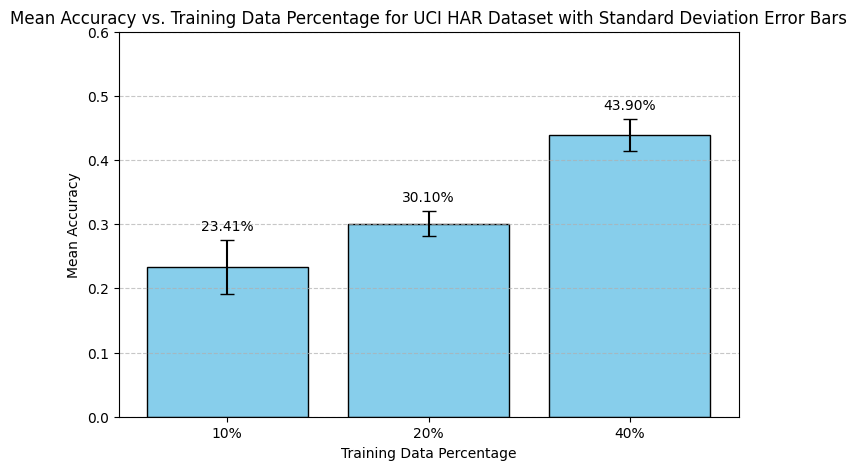

In [292]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd
import numpy as np

# # Individual accuracy values for each training data percentage
# # These are taken from the outputs of the respective model training cells
# accuracies_for_9_percent = [0.2014, 0.2935, 0.2073] # Corrected to match summary and mean calculations
# accuracies_for_18_percent = [0.2737, 0.3130, 0.3163] # Corrected to match summary and mean calculations
# accuracies_for_36_percent = [0.4316, 0.4124, 0.4730] # UPDATED with new accuracies

# Calculate mean accuracies
mean_accuracy_9 = np.mean(accuracies_for_9_percent)
mean_accuracy_18 = np.mean(accuracies_for_18_percent)
mean_accuracy_36 = np.mean(accuracies_for_36_percent)

# Calculate standard deviations
std_9_percent = np.std(accuracies_for_9_percent)
std_18_percent = np.std(accuracies_for_18_percent)
std_36_percent = np.std(accuracies_for_36_percent)

# Create a DataFrame for plotting, including mean accuracies and their standard deviations
plot_data = pd.DataFrame({
    'Training Data Percentage': ['10%', '20%', '40%'],
    'Mean Accuracy': [mean_accuracy_9, mean_accuracy_18, mean_accuracy_36],
    'Std Dev': [std_9_percent, std_18_percent, std_36_percent]
})

plt.figure(figsize=(8, 5))

# Create the bar plot
plt.bar(
    x=plot_data['Training Data Percentage'],
    height=plot_data['Mean Accuracy'],
    yerr=plot_data['Std Dev'], # Add error bars directly to the bars
    capsize=5, # Size of the caps on the error bars
    color='skyblue', # Color of the bars
    edgecolor='black' # Edge color of the bars
)

plt.title('Mean Accuracy vs. Training Data Percentage for UCI HAR Dataset with Standard Deviation Error Bars')
plt.xlabel('Training Data Percentage')
plt.ylabel('Mean Accuracy')
plt.ylim(0, 0.6) # Set y-axis limit to better visualize differences
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Add percentages above data points
for i, row in plot_data.iterrows():
    plt.text(i, row['Mean Accuracy'] + row['Std Dev'] + 0.01, # Position above error bar cap
             f'{row["Mean Accuracy"]*100:.2f}%',
             ha='center', va='bottom', fontsize=10, color='black')

plt.show()

# Corrected experiment pipeline
Run the corrected cell below instead of the earlier experiments. It executes `corrected_uchiar_experiment.py`, which creates valid windows before splitting and reports comparable 10%, 20%, and 40% results.

In [ ]:
%run corrected_uchiar_experiment.py
